# Height Estimation from Anthropometric Measurements

**Regression study · Exploratory analysis · Cross-validated model comparison**

This notebook investigates how recorded body measurements relate to height and compares several regression estimators on the same set of observations.

In [ ]:
import utils as ad

## 1. Research question and dataset

The objective is to estimate **height** from eleven recorded predictors: biacromial shoulder breadth, pelvic breadth, bitrochanteric breadth, chest depth, chest diameter, elbow diameter, wrist diameter, knee diameter, ankle diameter, age, and weight.

The dataset contains **507 observations** and **12 columns**, including the response (`height`). Because predictors are numerical, the notebook uses linear and regularized regression methods as well as Support Vector Regression (SVR). The exercise focuses on comparing modelling choices and interpreting diagnostics; it is not intended for clinical or identification use.

The workflow proceeds from data inspection and feature–target plots to single-feature baselines, multivariable models, a visual regression plane, and model comparisons using cross-validation. A temporary random feature is introduced for a visual sanity check but is **not included** in the model predictors.

## 2. Examine the input table

Load the CSV file and confirm its dimensions before looking at the available fields.

In [3]:
import pandas as pd

smd = pd.read_csv('data/body_measurements.csv')
print(smd.shape)

(507, 12)


The data-type and completeness report identifies the available predictors and highlights any null entries that would require preprocessing.

In [4]:
smd.info()

<class 'pandas.DataFrame'>
RangeIndex: 507 entries, 0 to 506
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   biacromial      507 non-null    float64
 1   pelvicBreadth   507 non-null    float64
 2   bitrochanteric  507 non-null    float64
 3   chestDepth      507 non-null    float64
 4   chestDiam       507 non-null    float64
 5   elbowDiam       507 non-null    float64
 6   wristDiam       507 non-null    float64
 7   kneeDiam        507 non-null    float64
 8   ankleDiam       507 non-null    float64
 9   age             507 non-null    int64  
 10  weight          507 non-null    float64
 11  height          507 non-null    float64
dtypes: float64(11), int64(1)
memory usage: 47.7 KB


Every field contains 507 non-null entries. The response and ten predictors are stored as floating-point measurements; `age` is an **integer-valued numeric predictor**, not a categorical variable. No missing entries are reported in the original table.

The next summary provides ranges and descriptive statistics. These statistics describe the observed sample but do not, by themselves, establish a distributional model or predictive relationship.

In [5]:
print(smd.describe())

       biacromial  pelvicBreadth  bitrochanteric  chestDepth   chestDiam  \
count  507.000000     507.000000      507.000000  507.000000  507.000000   
mean    38.811440      27.829980       31.980473   19.226036   27.973767   
std      3.059132       2.206308        2.030916    2.515877    2.741650   
min     32.400000      18.700000       24.700000   14.300000   22.200000   
25%     36.200000      26.500000       30.600000   17.300000   25.650000   
50%     38.700000      28.000000       32.000000   19.000000   27.800000   
75%     41.150000      29.250000       33.350000   20.900000   29.950000   
max     47.400000      34.700000       38.000000   27.500000   35.600000   

        elbowDiam   wristDiam    kneeDiam   ankleDiam         age      weight  \
count  507.000000  507.000000  507.000000  507.000000  507.000000  507.000000   
mean    13.385207   10.542604   18.810651   13.863314   30.181460   69.147535   
std      1.352906    0.944361    1.347595    1.247351    9.608472   13.3

### Descriptive observations

The recorded measurements span a range of body dimensions, while age and weight vary across the 507 observations. Feature scales differ, so coefficient sizes should not be compared directly without accounting for units. In particular, a wide range or a plausible biological relationship does not automatically imply that a variable will improve out-of-sample prediction.

The following plots examine each predictor against the recorded height. They are exploratory illustrations rather than statistical tests of significance.

### 2.1 Pairwise relationships with height

Scatter plots help reveal the direction, spread, and possible nonlinearity of each feature–height association. Each panel shows one predictor on its vertical axis and height on its horizontal axis.

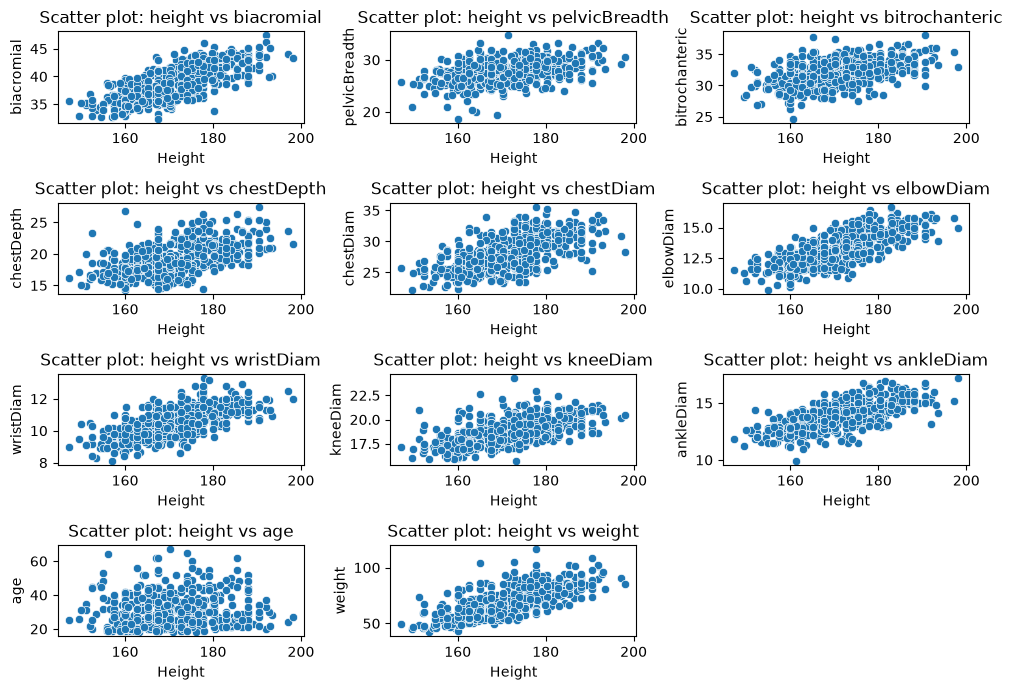

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

smd_atts_to_plot = ['biacromial', 'pelvicBreadth', 'bitrochanteric', 'chestDepth', 'chestDiam',
                   'elbowDiam', 'wristDiam', 'kneeDiam', 'ankleDiam', 'age', 'weight']

plt.figure(figsize=(10, 7))

for i, col in enumerate(smd_atts_to_plot, 1):
    plt.subplot(4, 3, i)
    sns.scatterplot(data=smd, x='height', y=col)
    plt.title(f'Scatter plot: height vs {col}')
    plt.xlabel('Height')
    plt.ylabel(col)

plt.tight_layout()
plt.show()

### 2.2 Add simple trend lines

A fitted line is overlaid on each feature–height scatter plot to make broad trends easier to compare. These lines are descriptive: they are not the final multivariable prediction models, and apparent slopes should not be interpreted causally.

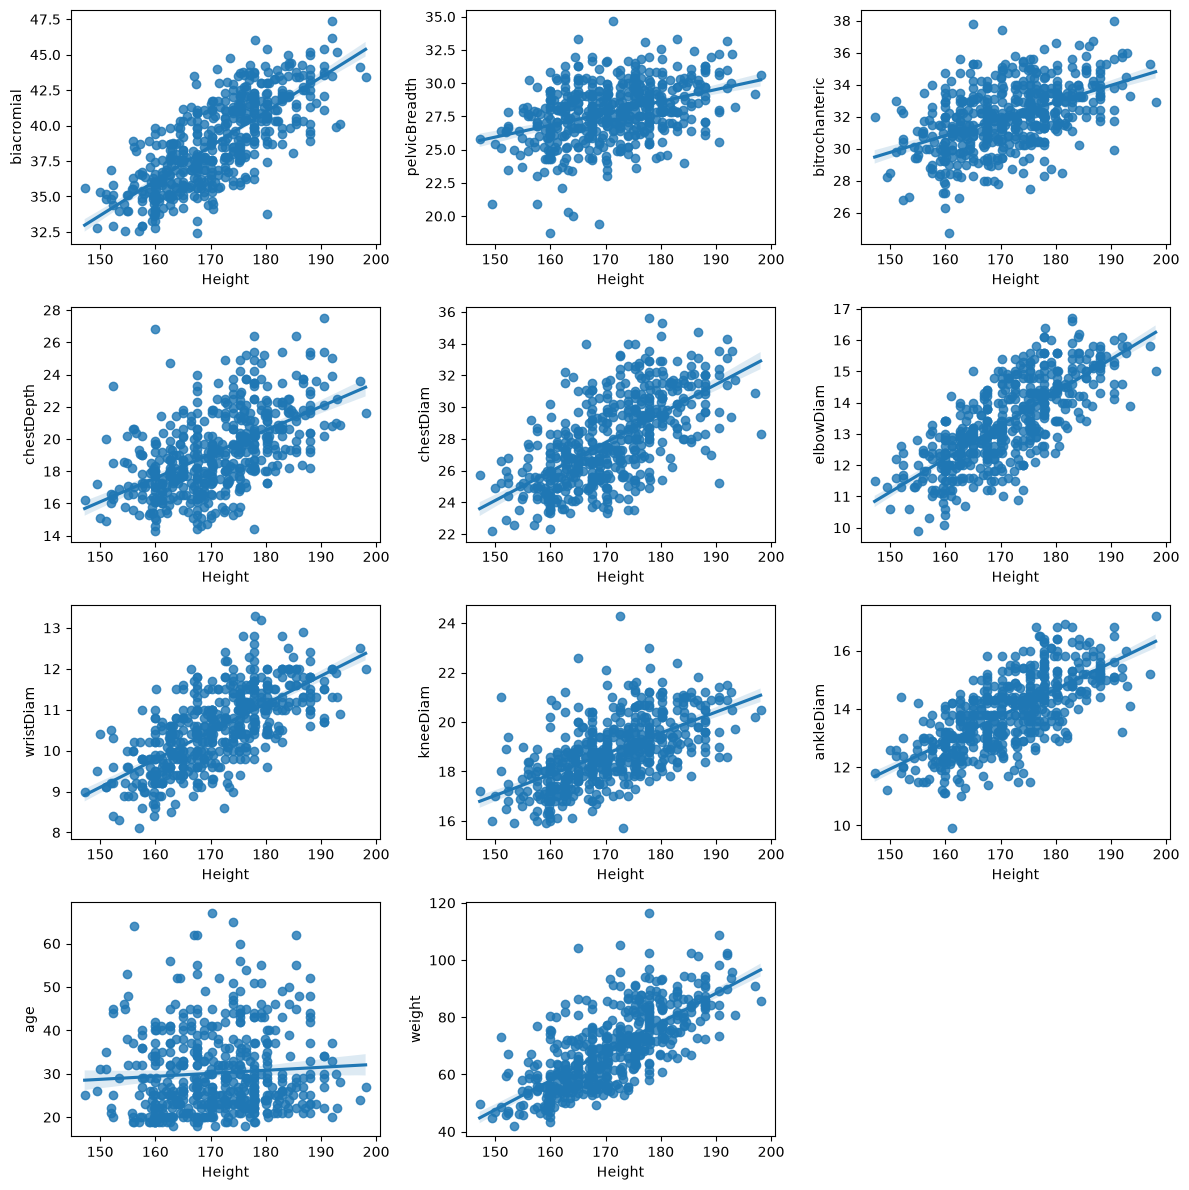

In [7]:
plt.figure(figsize=(12, 12)) 

for i, col in enumerate(smd_atts_to_plot, 1):
    plt.subplot(4, 3, i)
    sns.regplot(data=smd, x='height', y=col)
    # Panel titles are omitted to keep the small multiples uncluttered.
    plt.xlabel('Height')
    plt.ylabel(col)

plt.tight_layout()
plt.show()

Several skeletal measurements show upward trends with height, whereas the relationship involving age appears comparatively weak in these plots. The dispersion around the lines indicates that any single measurement leaves substantial individual variation unexplained.

Visual inspection can motivate candidate predictors, but model selection should be checked against cross-validated error rather than based on appearance alone.

### 2.3 A random-feature sanity check

To illustrate how an uninformative feature can appear in exploratory plots, create a separate copy of the dataset and append a uniformly distributed random column named `randomVariable`. The NumPy seed is fixed at `43` so the same values are generated on repeat runs.

In [8]:
import numpy as np

np.random.seed(43) 
smd_copy = smd.copy()
smd_copy['randomVariable'] = np.random.rand(len(smd))  

print(smd_copy.columns)  

Index(['biacromial', 'pelvicBreadth', 'bitrochanteric', 'chestDepth',
       'chestDiam', 'elbowDiam', 'wristDiam', 'kneeDiam', 'ankleDiam', 'age',
       'weight', 'height', 'randomVariable'],
      dtype='str')


The synthetic column is added only to `smd_copy`. Model fitting later uses `smd`, so this demonstration has **no effect** on the training features or reported regression metrics.

In [9]:
print(smd_copy.head())

   biacromial  pelvicBreadth  bitrochanteric  chestDepth  chestDiam  \
0        42.9           26.0            31.5        17.7       28.0   
1        43.7           28.5            33.5        16.9       30.8   
2        40.1           28.2            33.3        20.9       31.7   
3        44.3           29.9            34.0        18.4       28.2   
4        42.5           29.9            34.0        21.5       29.4   

   elbowDiam  wristDiam  kneeDiam  ankleDiam  age  weight  height  \
0       13.1       10.4      18.8       14.1   21    65.6   174.0   
1       14.0       11.8      20.6       15.1   23    71.8   175.3   
2       13.9       10.9      19.7       14.1   28    80.7   193.5   
3       13.9       11.2      20.9       15.0   23    72.6   186.5   
4       15.2       11.6      20.7       14.9   22    78.8   187.2   

   randomVariable  
0        0.115055  
1        0.609067  
2        0.133391  
3        0.240590  
4        0.327139  


Inspecting the first rows confirms that the artificial values appear alongside the original columns in the temporary data frame. The next figure checks whether they show an obvious visual association with height.

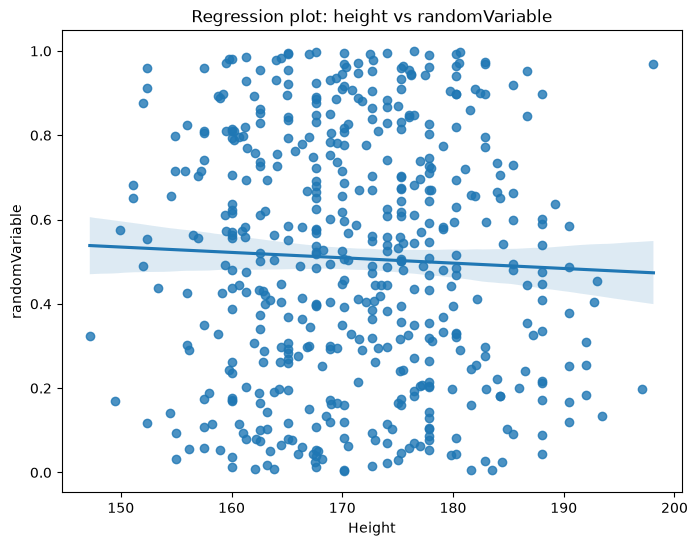

In [10]:
plt.figure(figsize=(8, 6))

sns.regplot(data=smd_copy, x='height', y='randomVariable')
plt.title('Regression plot: height vs randomVariable')
plt.xlabel('Height')
plt.ylabel('randomVariable')

plt.show()

The random-feature plot offers a useful contrast with the measured predictors: the fitted line is nearly flat and the points remain widely scattered. This supports the intuition that an unrelated random column is not a meaningful signal here. It does not, however, constitute a general hypothesis test.

## 3. Regression experiments

The following experiments retain the same dataset, estimator settings, and validation procedure while varying the number of predictors and the model family.

### 3.1 Ordinary least squares: one feature at a time

Start with simple linear regression using shoulder breadth (`biacromial`), elbow diameter (`elbowDiam`), and weight separately. Each cell reports cross-validation metrics before fitting the same estimator on the full dataset for an illustrative true-versus-predicted plot.

**Important:** the plotting predictions are computed on data used for fitting; they are not held-out test predictions. The cross-validation figures provide the more relevant model-comparison estimates.

In [11]:
from sklearn.linear_model import LinearRegression
# Separate the recorded height response from the eleven numeric predictors.
X_smd = smd[smd.columns.difference(['height'])]
y_smd = smd['height']

In [12]:
X_smd.head()

,age,ankleDiam,biacromial,bitrochanteric,chestDepth,chestDiam,elbowDiam,kneeDiam,pelvicBreadth,weight,wristDiam
0,21,14.1,42.9,31.5,17.7,28.0,13.1,18.8,26.0,65.6,10.4
1,23,15.1,43.7,33.5,16.9,30.8,14.0,20.6,28.5,71.8,11.8
2,28,14.1,40.1,33.3,20.9,31.7,13.9,19.7,28.2,80.7,10.9
3,23,15.0,44.3,34.0,18.4,28.2,13.9,20.9,29.9,72.6,11.2
4,22,14.9,42.5,34.0,21.5,29.4,15.2,20.7,29.9,78.8,11.6


Average cross-validated RMSE: 6.36 +/- 2.31
Average cross-validated R-squared: 0.24 +/- 0.21
Coefficients across all folds....
Coeficient:  [2.4644931] , Intercept:  75.54736906007341
Coeficient:  [2.17836973] , Intercept:  86.12627793443927
Coeficient:  [2.26872404] , Intercept:  83.04547499850237
Coeficient:  [2.22108238] , Intercept:  85.48561870760186
Coeficient:  [2.3445875] , Intercept:  80.13523816961542
Model coefficient:  [2.30302635]
Model intercept:  81.7600184502303


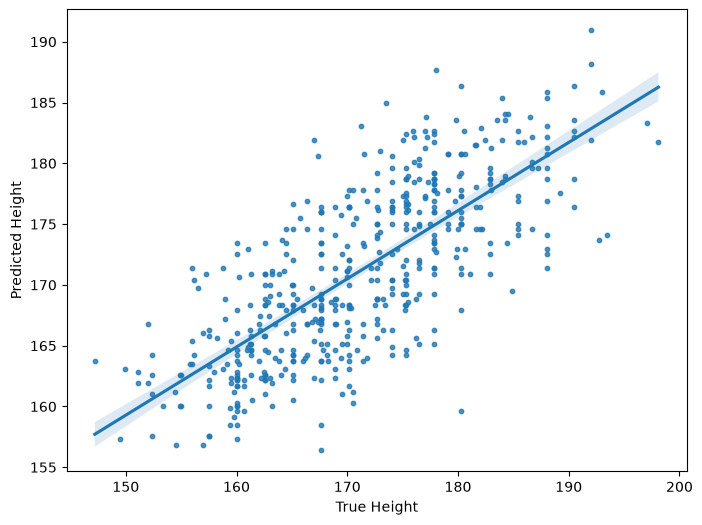

In [13]:
lr = LinearRegression()
# Estimate predictive performance across cross-validation folds.
ad.evaluate_regression_cv(lr, X_smd[['biacromial']], y_smd, lin=True, return_=True)
# Refit on the full sample for the illustrative prediction plot.
lr.fit(X_smd[['biacromial']], y_smd)
# Inspect the fitted slope and intercept.
print("Model coefficient: ", lr.coef_)
print("Model intercept: ", lr.intercept_)
# Generate in-sample predictions for visualization.
y_smd_pred = lr.predict(X_smd[['biacromial']])
# Compare observed and fitted height values visually.
plt.figure(figsize=(8,6))
sns.regplot(x=y_smd, y=y_smd_pred, scatter_kws={'s': 10})
# Leave the panel untitled; the axis labels identify the plotted values.
plt.xlabel("True Height")
plt.ylabel("Predicted Height")
plt.show()

Average cross-validated RMSE: 6.42 +/- 2.17
Average cross-validated R-squared: 0.21 +/- 0.23
Coefficients across all folds....
Coeficient:  [4.99140293] , Intercept:  103.79116214664673
Coeficient:  [5.01053771] , Intercept:  103.81899830292075
Coeficient:  [5.12440307] , Intercept:  102.70535018053826
Coeficient:  [5.22014467] , Intercept:  101.5049061427695
Coeficient:  [5.14043714] , Intercept:  102.65417838416711
Model coefficient:  [5.13234567]
Model intercept:  102.4462773401223


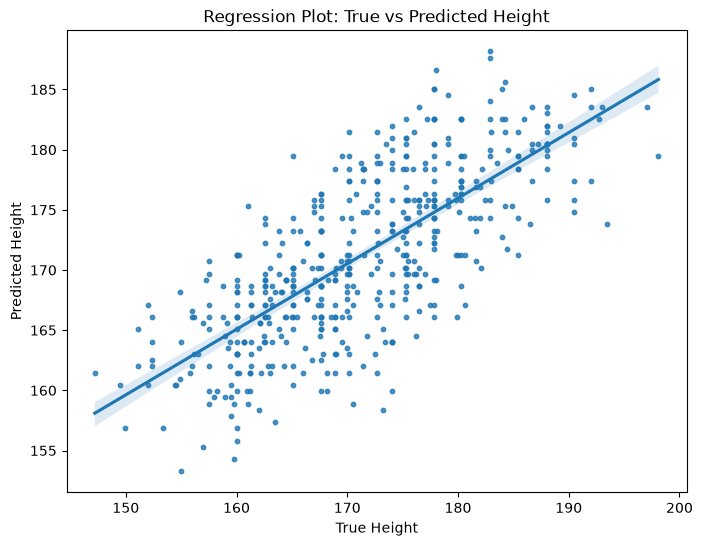

In [14]:
lr = LinearRegression()
# Summarize fold-level results for the elbow-diameter baseline.
ad.evaluate_regression_cv(lr, X_smd[['elbowDiam']], y_smd, lin=True, return_=True)
# Fit a complete-sample model for descriptive plotting.
lr.fit(X_smd[['elbowDiam']], y_smd)
# Display the estimated linear relationship.
print("Model coefficient: ", lr.coef_)
print("Model intercept: ", lr.intercept_)
# Obtain fitted values from the same records.
y_smd_pred = lr.predict(X_smd[['elbowDiam']])
# Visualize observed height against fitted height.
plt.figure(figsize=(8,6))
sns.regplot(x=y_smd, y=y_smd_pred, scatter_kws={'s': 10})
plt.title("Regression Plot: True vs Predicted Height")
plt.xlabel("True Height")
plt.ylabel("Predicted Height")
plt.show()

Average cross-validated RMSE: 6.79 +/- 2.93
Average cross-validated R-squared: 0.21 +/- 0.29
Coefficients across all folds....
Coeficient:  [0.47428922] , Intercept:  137.4405493987109
Coeficient:  [0.51635652] , Intercept:  135.13560123309736
Coeficient:  [0.49933326] , Intercept:  136.72052007153835
Coeficient:  [0.49039352] , Intercept:  137.8247903318451
Coeficient:  [0.52341472] , Intercept:  135.45531009311608
Model coefficient:  [0.50561356]
Model intercept:  136.181856102255


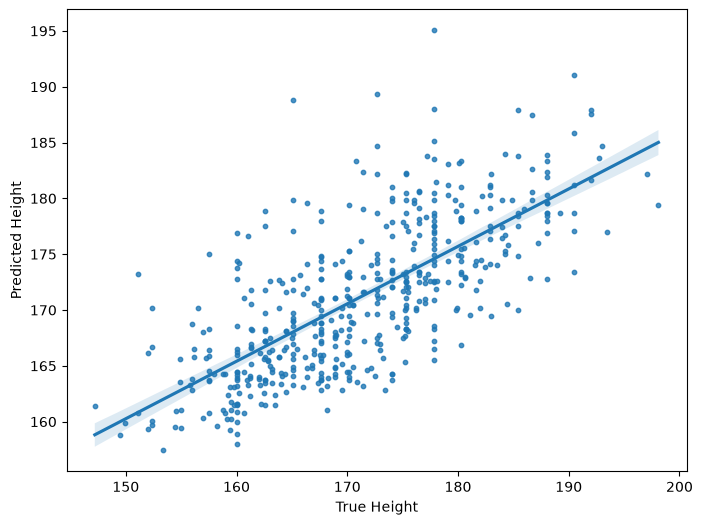

In [15]:
lr = LinearRegression()
# Assess the one-variable weight baseline using cross-validation.
ad.evaluate_regression_cv(lr, X_smd[['weight']], y_smd, lin=True, return_=True)
# Refit using all records before plotting.
lr.fit(X_smd[['weight']], y_smd)
# Report the estimated slope and intercept.
print("Model coefficient: ", lr.coef_)
print("Model intercept: ", lr.intercept_)
# Calculate full-sample fitted values for inspection.
y_smd_pred = lr.predict(X_smd[['weight']])
# Show the relationship between observed and fitted height.
plt.figure(figsize=(8,6))
sns.regplot(x=y_smd, y=y_smd_pred, scatter_kws={'s': 10})
# Axis labels provide the context without a separate title.
plt.xlabel("True Height")
plt.ylabel("Predicted Height")
plt.show()

Average cross-validated RMSE: 5.53 +/- 1.89
Average cross-validated R-squared: 0.38 +/- 0.19
Coefficients across all folds....
Coeficient:  [-0.05788615  1.81558372  1.49961002 -0.32644281 -0.54601203 -0.91963787
  1.61991078 -0.98825048  0.40109629  0.31720243 -0.04772787] , Intercept:  100.3061332637363
Coeficient:  [-0.08741576  1.22472675  1.13144938 -0.07747291 -0.22911329 -0.49018651
  1.72088039 -1.26237001  0.4471125   0.27770367  0.48406314] , Intercept:  97.4759191426929
Coeficient:  [-0.09939468  1.49883345  1.34516396 -0.06292214 -0.12483952 -0.76081592
  0.99052895 -1.15808844  0.48159033  0.24391376  1.11645578] , Intercept:  93.33635619678614
Coeficient:  [-0.06163883  1.59461772  1.39370103 -0.01528579 -0.26458542 -0.8090716
  1.76734593 -0.71317514  0.4368369   0.250669   -0.13297236] , Intercept:  86.62830454650994
Coeficient:  [-0.06954862  1.51472292  1.17635656  0.05132931 -0.18227139 -0.66140949
  1.24195274 -1.04695412  0.321673    0.28601357  0.53948141] , Inter

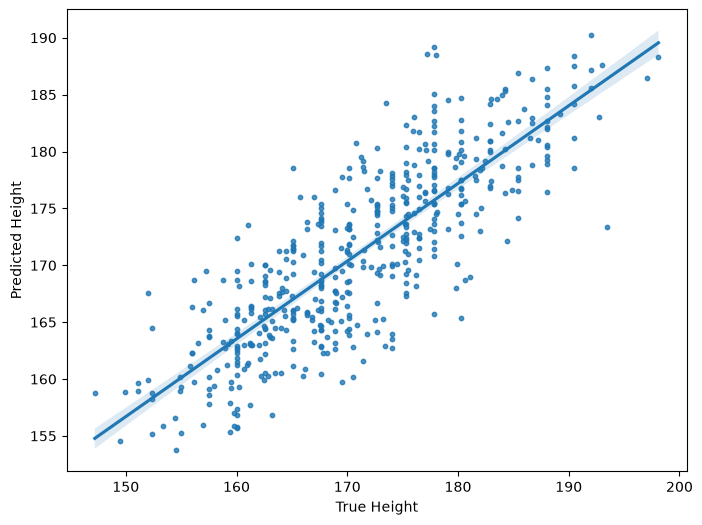

In [16]:
lr = LinearRegression()
# Evaluate the full feature set with the existing CV helper.
ad.evaluate_regression_cv(lr, X_smd, y_smd, lin=True, return_=True)
# Train on all observations for an in-sample visualization.
lr.fit(X_smd, y_smd)
# Display the multivariable coefficients and intercept.
print("Model coefficient: ", lr.coef_)
print("Model intercept: ", lr.intercept_)
# Calculate fitted heights for the training observations.
y_smd_pred = lr.predict(X_smd)
# Compare fitted heights against observed heights.
plt.figure(figsize=(8,6))
sns.regplot(x=y_smd, y=y_smd_pred, scatter_kws={'s': 10})
# The axis labels specify the comparison.
plt.xlabel("True Height")
plt.ylabel("Predicted Height")
plt.show()

### 3.2 A two-feature regression surface

Use `biacromial` and `pelvicBreadth` to construct a three-dimensional view of the fitted linear model: points represent observed measurements, and the surface represents the regression plane.

Plotly requires browser-side 3D rendering for this interactive figure. On a virtual machine, the plot may need a WebGL-capable browser; this visual limitation does not alter the regression computations.

Average cross-validated RMSE: 6.17 +/- 2.09
Average cross-validated R-squared: 0.28 +/- 0.20
Coefficients across all folds....
Coeficient:  [2.32224862 0.58774046] , Intercept:  64.66620130650132
Coeficient:  [2.0345404  0.71676864] , Intercept:  71.76867615909971
Coeficient:  [2.10008415 0.72170561] , Intercept:  69.45532798797647
Coeficient:  [2.10006511 0.76014639] , Intercept:  68.8881931880841
Coeficient:  [2.12457279 0.75438786] , Intercept:  67.92168991455794


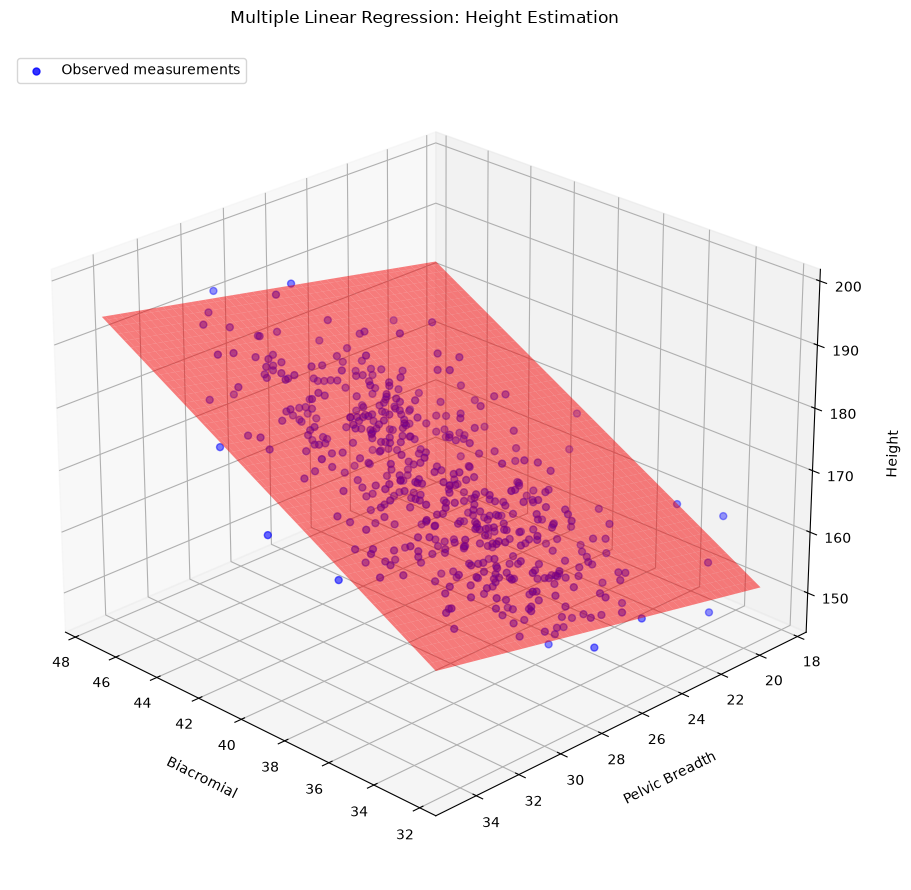

In [18]:
import matplotlib.pyplot as plt
import numpy as np

# Select the two predictors and the target variable.
X_smd_multi = smd[['biacromial', 'pelvicBreadth']]
y_smd = smd['height']

# Initialize the linear regression estimator.
lr = LinearRegression()

# Assess predictive performance through cross-validation.
ad.evaluate_regression_cv(
    lr,
    X_smd_multi,
    y_smd,
    lin=True,
    return_=True
)

# Fit the estimator using all available observations.
lr.fit(X_smd_multi, y_smd)

# Extract the intercept and individual feature coefficients.
intercept = lr.intercept_
biacromial_coef = lr.coef_[0]
pelvicBreadth_coef = lr.coef_[1]

# Generate evenly spaced values over the observed feature ranges.
biacromial_range = np.linspace(
    X_smd_multi['biacromial'].min(),
    X_smd_multi['biacromial'].max(),
    100
)

pelvicBreadth_range = np.linspace(
    X_smd_multi['pelvicBreadth'].min(),
    X_smd_multi['pelvicBreadth'].max(),
    100
)

# Construct the two-dimensional coordinate grid.
biacromial_range, pelvicBreadth_range = np.meshgrid(
    biacromial_range,
    pelvicBreadth_range
)

# Compute the fitted regression surface at each grid position.
preds = (
    intercept
    + biacromial_range * biacromial_coef
    + pelvicBreadth_range * pelvicBreadth_coef
)

# Initialize a three-dimensional Matplotlib figure.
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

# Plot the observed measurements as individual points.
ax.scatter(
    X_smd_multi['biacromial'],
    X_smd_multi['pelvicBreadth'],
    y_smd,
    color='blue',
    s=25,
    alpha=0.8,
    label='Observed measurements'
)

# Overlay the estimated regression plane.
ax.plot_surface(
    biacromial_range,
    pelvicBreadth_range,
    preds,
    color='red',
    alpha=0.5,
    edgecolor='none'
)

# Configure the coordinate axes.
ax.set_xlabel('Biacromial', labelpad=12)
ax.set_ylabel('Pelvic Breadth', labelpad=12)
ax.set_zlabel('Height', labelpad=12)

# Add a descriptive title and legend.
ax.set_title(
    'Multiple Linear Regression: Height Estimation',
    pad=20
)

ax.legend(loc='upper left')

# Set the viewing angle for the three-dimensional scene.
ax.view_init(elev=25, azim=135)

# Adjust the figure layout and display the visualization.
plt.tight_layout()
plt.show()

The interactive Plotly figure is produced by the cell above. Rotate the figure, when WebGL is available, to compare the regression plane with the observed points. No separate image file is required.

Average cross-validated RMSE: 5.53 +/- 1.89
Average cross-validated R-squared: 0.38 +/- 0.19
Coefficients across all folds....
Coeficient:  [-0.05788615  1.81558372  1.49961002 -0.32644281 -0.54601203 -0.91963787
  1.61991078 -0.98825048  0.40109629  0.31720243 -0.04772787] , Intercept:  100.3061332637363
Coeficient:  [-0.08741576  1.22472675  1.13144938 -0.07747291 -0.22911329 -0.49018651
  1.72088039 -1.26237001  0.4471125   0.27770367  0.48406314] , Intercept:  97.4759191426929
Coeficient:  [-0.09939468  1.49883345  1.34516396 -0.06292214 -0.12483952 -0.76081592
  0.99052895 -1.15808844  0.48159033  0.24391376  1.11645578] , Intercept:  93.33635619678614
Coeficient:  [-0.06163883  1.59461772  1.39370103 -0.01528579 -0.26458542 -0.8090716
  1.76734593 -0.71317514  0.4368369   0.250669   -0.13297236] , Intercept:  86.62830454650994
Coeficient:  [-0.06954862  1.51472292  1.17635656  0.05132931 -0.18227139 -0.66140949
  1.24195274 -1.04695412  0.321673    0.28601357  0.53948141] , Inter

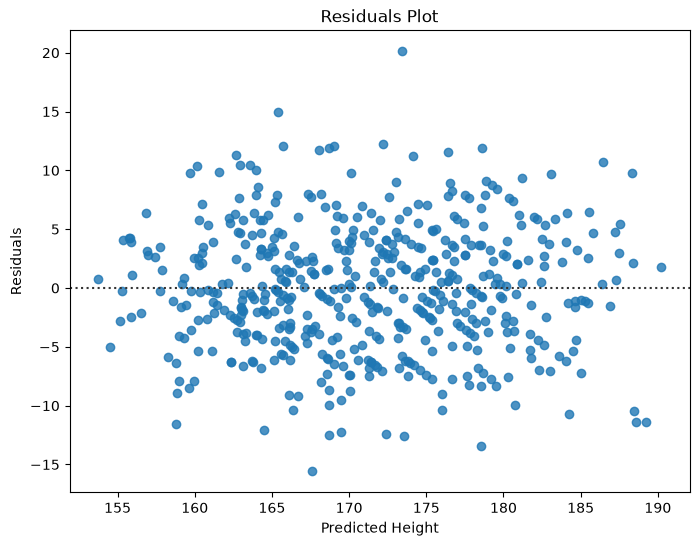

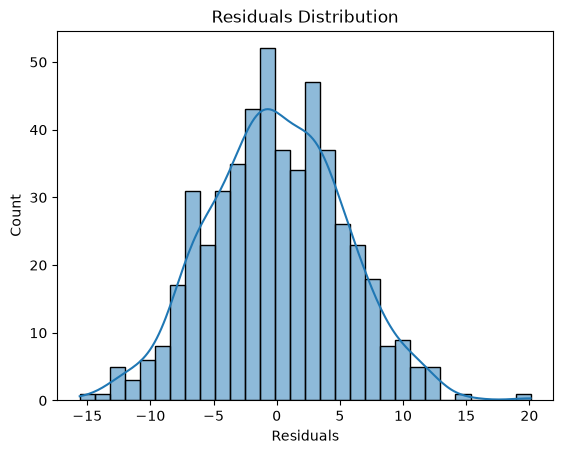

In [19]:
from sklearn.metrics import root_mean_squared_error, r2_score

lr = LinearRegression()
# Report the full-predictor cross-validation metrics again.
ad.evaluate_regression_cv(lr, X_smd, y_smd, lin=True, return_=True)
# Refit on all records for residual diagnostics.
lr.fit(X_smd, y_smd)
residuals = y_smd - y_smd_pred
# Inspect errors relative to the model predictions.
plt.figure(figsize=(8, 6))
sns.residplot(x=y_smd_pred, y=residuals, line_kws={'color': 'red', 'lw': 2})
plt.xlabel("Predicted Height")
plt.ylabel("Residuals")
plt.title("Residuals Plot")
plt.show()
# Examine the residual distribution as an additional visual diagnostic.
sns.histplot(residuals, kde=True, bins=30)
plt.title("Residuals Distribution")
plt.xlabel("Residuals")
plt.show()

In [20]:
pd.set_option('display.max_rows', None)  # Display the full printed series without truncation.

# Print the residual values used in the diagnostics.
print("\nResiduals Plot Data:")
print("Residuals:")
print(residuals) 


Residuals Plot Data:
Residuals:
0      -1.823641
1      -3.697075
2      20.101699
3       5.354343
4       6.219927
5       3.628873
6      -0.998733
7       1.903673
8      -1.917588
9       2.385325
10      5.530597
11     -7.214164
12      1.768520
13      3.062913
14     -2.958559
15      5.303569
16      9.653134
17     -6.822208
18     -5.302629
19     -7.036993
20      1.401637
21      0.892642
22     -2.561318
23     -2.797178
24    -10.737059
25    -10.470804
26     -4.378853
27      4.104061
28     -4.377849
29      1.401450
30     -1.103507
31      0.971404
32      7.387629
33      5.864071
34      0.745472
35     -3.315883
36      8.975466
37     -1.338008
38      6.951094
39     -1.102719
40      7.895577
41     -7.771415
42     -1.904576
43      1.641690
44     -1.478078
45     -1.288713
46      8.742568
47    -11.406600
48     -3.659269
49     -2.405085
50     -8.271132
51     -1.298455
52     -2.679044
53      3.654642
54     -3.511145
55     -4.110396
56      0.15645

### 3.3 Interpreting the multivariable baseline

The regression using all eleven predictors reports **cross-validated RMSE ≈ 5.53** and a score labelled "R-squared" of approximately **0.38**. That score is calculated by the helper using scikit-learn's `explained_variance` metric, so it should not be described as a separately computed coefficient of determination.

The observed-versus-predicted scatter and residual diagnostics in the preceding cells are computed with an estimator fitted on the full dataset. They provide a useful in-sample diagnostic, but must not be compared as though they were a held-out evaluation.

The residual scatter and distribution can expose systematic patterns or extreme errors. A visually symmetric histogram alone does not establish residual normality or predictive reliability.

### 3.4 Comparing models using the recorded validation protocol

The notebook uses five-fold cross-validation to compare estimators. Its helper prints the square root of mean cross-validated MSE as **RMSE** and prints mean **explained variance** under the label "R-squared". The figures are retained exactly as generated; the accompanying narrative uses the proper metric interpretation.

The subsequent searches tune SVR and ElasticNet over fixed hyperparameter grids. Hyperparameters are selected using cross-validation on the available observations, and the selected models are evaluated again on those same observations. Those later scores should be read as exploratory comparisons, **not** independent estimates from a previously unseen test set.

### 3.5 Support Vector Regression

SVR is tuned across four kernels and several `C` and `epsilon` values. The selection criterion is negative mean squared error, with five-fold cross-validation.

In [21]:
from sklearn.svm import SVR
from sklearn.model_selection import cross_validate
from sklearn.model_selection import GridSearchCV

# Set up an SVR estimator for parameter selection.
svr = SVR()

# Compare kernels and the C and epsilon settings.
param_grid = {
    'kernel': ['linear', 'rbf', 'poly', 'sigmoid'],
    'C': [0.1, 1, 10, 50],
    'epsilon': [0.1, 0.5, 1]
}

# Select parameters by five-fold mean squared error.
grid_search = GridSearchCV(estimator=svr, param_grid=param_grid, scoring='neg_mean_squared_error', cv=5, n_jobs=-1)
grid_search.fit(X_smd, y_smd)  # Fit the search on the same feature and target arrays.

# Extract the selected SVR estimator and its settings.
best_svr = grid_search.best_estimator_
best_params = grid_search.best_params_

print(f"Best SVR parameters: {best_params}")


# Report metrics for the chosen estimator using the shared helper.
print("\nPerforming cross-validation using the best SVR model:")
ad.evaluate_regression_cv(best_svr, X_smd, y_smd, lin=False)

Best SVR parameters: {'C': 10, 'epsilon': 1, 'kernel': 'poly'}

Performing cross-validation using the best SVR model:
Average cross-validated RMSE: 5.54 +/- 2.21
Average cross-validated R-squared: 0.38 +/- 0.18


The saved search output selects **`C=10`, `epsilon=1`, and `kernel='poly'`**. With this configuration, the notebook reports **cross-validated RMSE ≈ 5.54** and **explained variance ≈ 0.38**.

These results are close to the multivariable linear baseline. In this experiment, the selected nonlinear SVR did not demonstrate a large improvement under the reported validation procedure. The grid search and its subsequent evaluation use the same available data, so the scores are best treated as exploratory rather than as an untouched-test estimate.

### 3.6 Regularized linear models

The final experiments compare ElasticNet with Ridge regression using the same eleven candidate predictors. Regularization constrains model coefficients and can be useful when features carry overlapping information.

**ElasticNet** combines L1 and L2 penalties. The notebook first evaluates default parameters, then searches a fixed grid of `alpha` and `l1_ratio` settings. The grid search chooses parameters by mean squared error, while the helper reports RMSE and explained variance for the selected estimator.

**Ridge** uses an L2 penalty. The final cells evaluate a default Ridge model and compare several `alpha` settings. Because these are closely related linear models, small metric differences should not be overstated.

In [22]:
from sklearn.linear_model import ElasticNet

# Start with the default ElasticNet estimator.
elastic_net = ElasticNet()

# Evaluate the untuned baseline using cross-validation.
print("\nPerforming cross-validation using the best ElasticNet model:")
ad.evaluate_regression_cv(elastic_net, X_smd, y_smd, lin=True)


Performing cross-validation using the best ElasticNet model:
Average cross-validated RMSE: 5.65 +/- 1.85
Average cross-validated R-squared: 0.37 +/- 0.18
Coefficients across all folds....
Coeficient:  [-0.05682494  0.74807678  1.28221958 -0.         -0.04916952 -0.25314105
  0.53475264 -0.          0.14306997  0.22914009  0.        ] , Intercept:  93.52072535584395
Coeficient:  [-0.08621994  0.47576045  0.96596198  0.         -0.         -0.
  0.60758388 -0.          0.19463954  0.25648625  0.        ] , Intercept:  98.16991474311115
Coeficient:  [-0.08058612  0.65902845  1.19098195 -0.          0.         -0.17154706
  0.42382667 -0.          0.23651094  0.23281885  0.04828508] , Intercept:  94.15917949257309
Coeficient:  [-0.06244787  0.58116399  1.17084945  0.         -0.         -0.21950489
  0.60637169  0.          0.16772495  0.25142518  0.        ] , Intercept:  95.74371310635273
Coeficient:  [-0.04871361  0.6509931   1.00047861  0.         -0.         -0.11670186
  0.5048802  

In [23]:
from sklearn.linear_model import ElasticNet

# Construct the estimator to be tuned.
elastic_net = ElasticNet()

# Search a fixed set of penalty strengths and mixtures.
param_grid = {
    'alpha': [0.1, 0.5, 1, 10],  # Strength of the overall penalty.
    'l1_ratio': [0.1, 0.5, 0.9]  # Balance between L1 and L2 penalties.
}

# Select the configuration by cross-validated MSE.
grid_search = GridSearchCV(estimator=elastic_net, param_grid=param_grid, cv=5, scoring='neg_mean_squared_error')
grid_search.fit(X_smd, y_smd)  # Use the same feature and response arrays as the other models.

# Read the parameter combination selected by the search.
best_params = grid_search.best_params_
print(f"Best ElasticNet parameters: {best_params}")

# Retain the selected fitted estimator.
best_model = grid_search.best_estimator_

# Summarize its fold-level performance for comparison.
print("\nPerforming cross-validation using the best ElasticNet model:")
ad.evaluate_regression_cv(best_model, X_smd, y_smd, lin=True)

Best ElasticNet parameters: {'alpha': 0.1, 'l1_ratio': 0.1}

Performing cross-validation using the best ElasticNet model:
Average cross-validated RMSE: 5.51 +/- 1.80
Average cross-validated R-squared: 0.39 +/- 0.18
Coefficients across all folds....
Coeficient:  [-0.05880678  1.56698148  1.48246208 -0.29995345 -0.46900486 -0.82707934
  1.37117628 -0.75562437  0.38441259  0.29992064  0.15027329] , Intercept:  98.062446410333
Coeficient:  [-0.08882965  1.09479288  1.11389967 -0.0728998  -0.18642163 -0.41513771
  1.45213027 -0.94189453  0.41433986  0.26783637  0.4611759 ] , Intercept:  96.28761117916773
Coeficient:  [-0.0972662   1.32672827  1.3306518  -0.06473247 -0.09352115 -0.682512
  0.94657547 -0.89201069  0.45497391  0.23834951  0.8758286 ] , Intercept:  92.73417100393509
Coeficient:  [-0.06247379  1.37735815  1.36751483 -0.         -0.22473327 -0.7352083
  1.48007313 -0.50064933  0.39551607  0.2487641   0.03925523] , Intercept:  86.72534218285709
Coeficient:  [-0.06718468  1.3361783

In [24]:
from sklearn.linear_model import Ridge
ridge = Ridge(random_state=34)
ad.evaluate_regression_cv(ridge, X_smd, y_smd, lin=True)

Average cross-validated RMSE: 5.53 +/- 1.88
Average cross-validated R-squared: 0.38 +/- 0.19
Coefficients across all folds....
Coeficient:  [-0.05793334  1.80742183  1.49922621 -0.32586276 -0.54370926 -0.91709334
  1.61147369 -0.98133765  0.400925    0.31664055 -0.03810092] , Intercept:  100.22703439463858
Coeficient:  [-0.08745526  1.22106936  1.13106242 -0.07764366 -0.2279599  -0.48817383
  1.71206098 -1.25253947  0.44630478  0.27741951  0.48461787] , Intercept:  97.43768873455132
Coeficient:  [-0.09931835  1.49363631  1.34485647 -0.06333482 -0.12412855 -0.75870624
  0.99041155 -1.15008094  0.48097301  0.24378906  1.10800522] , Intercept:  93.32445613970769
Coeficient:  [-0.06168003  1.58796083  1.39304581 -0.01491832 -0.26344724 -0.8071692
  1.75756968 -0.70715941  0.43583387  0.25061151 -0.12461041] , Intercept:  86.62327526091427
Coeficient:  [-0.06947992  1.50927287  1.17596764  0.05111463 -0.18115527 -0.65981687
  1.23848166 -1.03999189  0.32119309  0.28587921  0.5385689 ] , Int

Average cross-validated RMSE: 5.53 +/- 1.89
Average cross-validated R-squared: 0.38 +/- 0.19
Average cross-validated RMSE: 5.53 +/- 1.89
Average cross-validated R-squared: 0.38 +/- 0.19
Average cross-validated RMSE: 5.53 +/- 1.89
Average cross-validated R-squared: 0.38 +/- 0.19
Average cross-validated RMSE: 5.53 +/- 1.89
Average cross-validated R-squared: 0.38 +/- 0.19
Average cross-validated RMSE: 5.53 +/- 1.89
Average cross-validated R-squared: 0.38 +/- 0.19
Average cross-validated RMSE: 5.53 +/- 1.89
Average cross-validated R-squared: 0.38 +/- 0.19
Average cross-validated RMSE: 5.53 +/- 1.89
Average cross-validated R-squared: 0.38 +/- 0.19
Average cross-validated RMSE: 5.53 +/- 1.89
Average cross-validated R-squared: 0.38 +/- 0.19
Average cross-validated RMSE: 5.53 +/- 1.89
Average cross-validated R-squared: 0.38 +/- 0.19
Average cross-validated RMSE: 5.53 +/- 1.89
Average cross-validated R-squared: 0.38 +/- 0.19
Average cross-validated RMSE: 5.53 +/- 1.89
Average cross-validated R-

Text(0, 0.5, 'R-Squared')

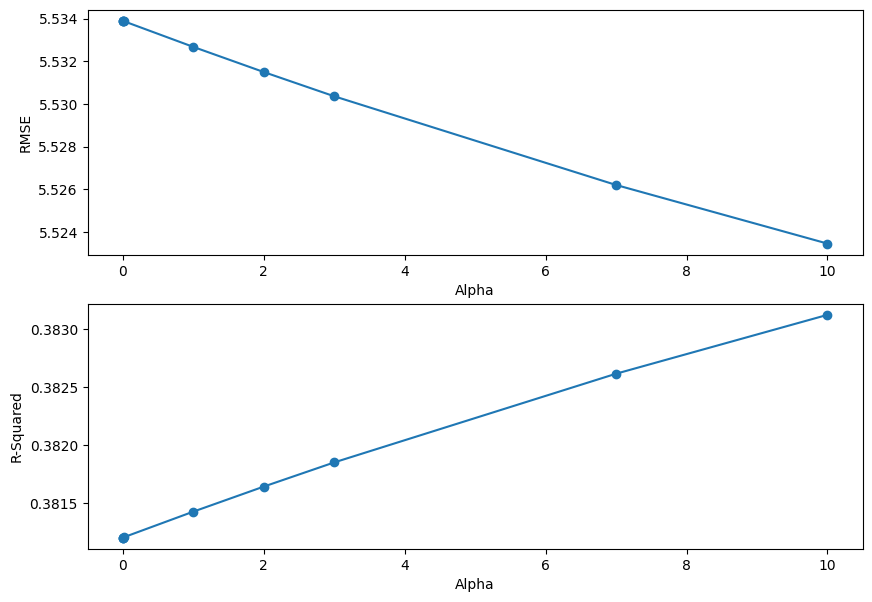

In [29]:
alphas = [1e-8, 1e-7, 1e-3, 1e-2, 1, 2, 3, 7, 10]
rmses = []
r2s = []
for alpha in alphas:
  ridge = Ridge(alpha=alpha, random_state=34)
  ad.evaluate_regression_cv(ridge, X_smd, y_smd, lin=False, return_=True)
  rmses.append(ad.evaluate_regression_cv(ridge, X_smd, y_smd, lin=False, return_=True)[0])
  r2s.append(ad.evaluate_regression_cv(ridge, X_smd, y_smd, lin=False, return_=True)[1])

plt.figure(figsize=(10,7))
plt.subplot(2, 1, 1)
plt.plot(alphas, rmses, marker='o')
plt.xlabel('Alpha')
plt.ylabel('RMSE')
plt.subplot(2, 1, 2)
plt.plot(alphas, r2s, marker='o')
plt.xlabel('Alpha')
plt.ylabel('R-Squared')

## 4. Consolidated model comparison

The table below transcribes the values already stored in this notebook. It does **not** rerun the models.

| Estimator / feature set | CV RMSE | CV explained variance* |
|---|---:|---:|
| Linear regression — shoulder breadth only | 6.36 | 0.24 |
| Linear regression — elbow diameter only | 6.42 | 0.21 |
| Linear regression — weight only | 6.79 | 0.21 |
| Linear regression — all eleven predictors | 5.53 | 0.38 |
| Linear regression — shoulder + pelvic breadth | 6.17 | 0.28 |
| Default ElasticNet — all predictors | 5.65 | 0.37 |
| Tuned ElasticNet — all predictors | 5.51 | 0.39 |
| Ridge — all predictors | 5.53 | 0.38 |
| Tuned SVR — all predictors | 5.54 | 0.38 |

*The shared helper calls its second value "R-squared" in printed output, but uses the `explained_variance` scoring function. The table labels it according to the implemented scoring method.

**Interpretation.** Multiple predictors substantially improve on the single-feature baselines. Tuned ElasticNet yields the lowest reported RMSE in this selection, but the differences among the multivariable estimators are small. These are exploratory cross-validation scores, not independent test-set results. The dataset and modelling choices have not been modified in this revision.
